In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Pengaturan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Impor dataset
print("Memuat dataset Online Retail.xlsx...")
start_time = time.time()
df = pd.read_excel('Online Retail.xlsx')
print(f"Dataset berhasil dimuat dalam {time.time() - start_time:.2f} detik.\n")

# Tampilkan 5 baris pertama
print("=== 5 Baris Pertama Dataset (df.head()) ===")
display(df.head())


Memuat dataset Online Retail.xlsx...
Dataset berhasil dimuat dalam 37.87 detik.

=== 5 Baris Pertama Dataset (df.head()) ===


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Tampilkan dimensi dataset (df.shape)
print("=== Dimensi Dataset (df.shape) ===")
print(f"Jumlah baris : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]}")


=== Dimensi Dataset (df.shape) ===
Jumlah baris : 541,909
Jumlah kolom : 8


In [3]:
# Tampilkan informasi tipe data dan missing value (df.info())
print("=== Struktur dan Tipe Data (df.info()) ===")
df.info()


=== Struktur dan Tipe Data (df.info()) ===
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


### Ringkasan Pemahaman Struktur Dataset:
1. **Dimensi Awal**: Dataset memiliki **541,909 baris** dan **8 kolom**.
2. **Atribut Dataset**:
   - `InvoiceNo` (object): Nomor faktur unik 6 digit per transaksi. Jika diawali huruf 'C', menunjukkan transaksi pembatalan (cancellation).
   - `StockCode` (object): Kode unik produk/barang.
   - `Description` (object): Nama deskripsi produk. Terdapat nilai kosong/missing yang perlu ditangani.
   - `Quantity` (int64): Jumlah unit produk yang dibeli per transaksi. Terdapat nilai negatif yang mengindikasikan retur barang.
   - `InvoiceDate` (datetime64): Tanggal dan waktu transaksi dilakukan.
   - `UnitPrice` (float64): Harga produk per unit dalam Pound Sterling (£).
   - `CustomerID` (float64): Nomor pengenal pelanggan unik. Terdapat cukup banyak *missing values*.
   - `Country` (object): Nama negara tempat pelanggan berdomisili.


In [4]:
# Hitung metrik awal sebelum pembersihan
rows_before = len(df)
invoices_before = df['InvoiceNo'].nunique()

print(f"Jumlah baris sebelum pembersihan   : {rows_before:,}")
print(f"Jumlah invoice sebelum pembersihan : {invoices_before:,}\n")

# 1. Hapus baris dengan Description kosong / NaN
df_clean = df.dropna(subset=['Description']).copy()

# Bersihkan spasi kosong berlebih di awal/akhir nama deskripsi
df_clean['Description'] = df_clean['Description'].astype(str).str.strip()
df_clean = df_clean[df_clean['Description'] != '']

# 2. Hapus transaksi yang dibatalkan (InvoiceNo diawali huruf 'C')
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str).str.strip()
df_clean = df_clean[~df_clean['InvoiceNo'].str.upper().str.startswith('C')]

# 3. Hapus baris dengan Quantity bernilai negatif atau nol
df_clean = df_clean[df_clean['Quantity'] > 0]

# Hitung metrik setelah pembersihan
rows_after = len(df_clean)
invoices_after = df_clean['InvoiceNo'].nunique()

print(f"Jumlah baris sesudah pembersihan   : {rows_after:,}")
print(f"Jumlah invoice sesudah pembersihan : {invoices_after:,}")


Jumlah baris sebelum pembersihan   : 541,909
Jumlah invoice sebelum pembersihan : 25,900

Jumlah baris sesudah pembersihan   : 530,693
Jumlah invoice sesudah pembersihan : 20,136


In [5]:
# Tabel perbandingan sebelum vs sesudah pembersihan
comparison_df = pd.DataFrame({
    'Metrik': ['Jumlah Baris Data', 'Jumlah Faktur/Invoice Unik'],
    'Sebelum Pembersihan': [f"{rows_before:,}", f"{invoices_before:,}"],
    'Sesudah Pembersihan': [f"{rows_after:,}", f"{invoices_after:,}"],
    'Selisih (Tereliminasi)': [f"{rows_before - rows_after:,}", f"{invoices_before - invoices_after:,}"],
    'Persentase Berkurang (%)': [
        f"{((rows_before - rows_after) / rows_before) * 100:.2f}%",
        f"{((invoices_before - invoices_after) / invoices_before) * 100:.2f}%"
    ]
})

display(comparison_df)


,Metrik,Sebelum Pembersihan,Sesudah Pembersihan,Selisih (Tereliminasi),Persentase Berkurang (%)
0,Jumlah Baris Data,"541,909","530,693","11,216",2.07%
1,Jumlah Faktur/Invoice Unik,"25,900","20,136","5,764",22.25%


### Analisis Hasil Pembersihan Data:
- Terjadi eliminasi sebanyak **11,216 baris data (2.07%)** yang terdiri atas transaksi tanpa deskripsi item, pembatalan pesanan (cancellation/refund), dan kuantitas non-positif.
- Jumlah transaksi (*unique invoices*) berkurang dari **25,900** menjadi **20,136 faktur valid (penurunan 22.25%)**. Hal ini mengindikasikan bahwa cukup banyak nomor invoice awal merupakan faktur retur/pembatalan (`Cxxxxx`) yang memang tidak boleh disertakan dalam analisis keranjang belanja barang yang dibeli bersamaan.


In [6]:
from mlxtend.preprocessing import TransactionEncoder

# 1. Format transaksi berbasis invoice (daftar produk per transaksi)
print("Mengelompokkan produk berdasarkan InvoiceNo...")
transactions = (
    df_clean.groupby('InvoiceNo')['Description']
    .apply(lambda s: list(set(s)))
    .tolist()
)

print(f"Total transaksi keranjang belanja yang terbentuk: {len(transactions):,}\n")

# Tampilkan sampel 3 transaksi pertama
print("=== Contoh 3 Transaksi Pertama ===")
for i, t in enumerate(transactions[:3], 1):
    print(f"Transaksi {i} ({len(t)} item): {t[:5]} ...")


Mengelompokkan produk berdasarkan InvoiceNo...
Total transaksi keranjang belanja yang terbentuk: 20,136

=== Contoh 3 Transaksi Pertama ===
Transaksi 1 (7 item): ['RED WOOLLY HOTTIE WHITE HEART.', 'SET 7 BABUSHKA NESTING BOXES', 'CREAM CUPID HEARTS COAT HANGER', 'WHITE HANGING HEART T-LIGHT HOLDER', 'GLASS STAR FROSTED T-LIGHT HOLDER'] ...
Transaksi 2 (2 item): ['HAND WARMER RED POLKA DOT', 'HAND WARMER UNION JACK'] ...
Transaksi 3 (12 item): ['HOME BUILDING BLOCK WORD', "POPPY'S PLAYHOUSE BEDROOM", 'DOORMAT NEW ENGLAND', 'BOX OF VINTAGE ALPHABET BLOCKS', 'IVORY KNITTED MUG COSY'] ...


In [7]:
# 2. Transformasi ke bentuk one-hot encoded matrix menggunakan TransactionEncoder
print("Mentransformasikan ke bentuk matriks one-hot (basket)...")
t0 = time.time()
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_basket = pd.DataFrame(te_ary, columns=te.columns_)

print(f"Transformasi selesai dalam {time.time() - t0:.2f} detik.")
print(f"Dimensi matriks basket: {df_basket.shape[0]:,} transaksi x {df_basket.shape[1]:,} item produk unik\n")

# Tampilkan sampel 5 baris pertama dari basket matrix (10 kolom pertama)
print("=== Sampel Matriks One-Hot (5 baris x 10 item) ===")
display(df_basket.iloc[:5, :10])


Mentransformasikan ke bentuk matriks one-hot (basket)...
Transformasi selesai dalam 0.84 detik.
Dimensi matriks basket: 20,136 transaksi x 4,065 item produk unik

=== Sampel Matriks One-Hot (5 baris x 10 item) ===


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False


In [8]:
from mlxtend.frequent_patterns import fpgrowth, association_rules

# Titik awal: min_support = 0.01
print("=== Menjalankan FP-Growth (min_support = 0.01) ===")
t0 = time.time()
frequent_itemsets_initial = fpgrowth(df_basket, min_support=0.01, use_colnames=True)
print(f"Waktu eksekusi FP-Growth : {time.time() - t0:.2f} detik")
print(f"Jumlah frequent itemsets : {len(frequent_itemsets_initial):,}\n")

# Pembangkitan association rules: min_confidence = 0.5
print("=== Membangkitkan Aturan Asosiasi (min_confidence = 0.5) ===")
t0 = time.time()
rules_initial = association_rules(frequent_itemsets_initial, metric='confidence', min_threshold=0.5)
print(f"Waktu pembangkitan rules : {time.time() - t0:.2f} detik")
print(f"Jumlah aturan asosiasi   : {len(rules_initial):,}")


=== Menjalankan FP-Growth (min_support = 0.01) ===
Waktu eksekusi FP-Growth : 5.88 detik
Jumlah frequent itemsets : 1,853

=== Membangkitkan Aturan Asosiasi (min_confidence = 0.5) ===
Waktu pembangkitan rules : 0.01 detik
Jumlah aturan asosiasi   : 841


### Analisis dan Penyesuaian Nilai Threshold

Pada pengujian titik awal dengan **min_support = 0.01** dan **min_confidence = 0.5**:
- Dihasilkan **1,853 frequent itemset** dan **841 aturan asosiasi**.
- **Evaluasi**:
  Jumlah **841 aturan asosiasi tergolong terlalu banyak (*overwhelming*)** untuk diimplementasikan langsung dalam strategi ritel operasional. Banyak aturan yang dihasilkan merupakan kombinasi permutasi item serupa atau produk yang memiliki support marjinal (hanya muncul di ~200 transaksi dari total 20,136 transaksi).
- **Eksperimen Penyesuaian Parameter**:
  Untuk menemukan titik keseimbangan (*sweet spot*) yang menghasilkan aturan yang padat, bernilai praktis, dan dapat ditindaklanjuti secara manajerial, kita menguji beberapa variasi ambang batas `min_support` (0.01, 0.015, 0.02, 0.03) dan `min_confidence` (0.5, 0.6, 0.7).


In [9]:
# Eksplorasi perbandingan variasi threshold support dan confidence
tuning_records = []

for s in [0.01, 0.015, 0.02, 0.03]:
    fi = fpgrowth(df_basket, min_support=s, use_colnames=True)
    n_fi = len(fi)
    for c in [0.5, 0.6, 0.7]:
        r = association_rules(fi, metric='confidence', min_threshold=c)
        n_rules = len(r)
        tuning_records.append({
            'Min Support': s,
            'Min Confidence': c,
            'Frequent Itemsets': n_fi,
            'Association Rules': n_rules
        })

df_tuning = pd.DataFrame(tuning_records)
display(df_tuning)


,Min Support,Min Confidence,Frequent Itemsets,Association Rules
0,0.010,0.5,1853,841
1,0.010,0.6,1853,498
2,0.010,0.7,1853,260
3,0.015,0.5,695,177
4,0.015,0.6,695,94
5,0.015,0.7,695,41
6,0.020,0.5,376,61
7,0.020,0.6,376,31
8,0.020,0.7,376,13
9,0.030,0.5,136,11


### Alasan Penyesuaian:
Dari tabel pengujian di atas:
1. **min_support = 0.03**: Aturan yang dihasilkan sangat sedikit (hanya 11 aturan pada confidence 0.5 dan 3 aturan pada confidence 0.7), sehingga potensi *cross-selling* dari produk berkategori niche terlewatkan.
2. **min_support = 0.015**: Memberikan titik keseimbangan optimal dengan menghasilkan **177 aturan** pada confidence 0.5 dan **94 aturan** pada confidence 0.6. Kumpulan aturan ini cukup variatif, bebas dari noise transaksi acak, dan terfokus pada produk dengan frekuensi pembelian yang signifikan.
3. Kita dapat tetap mempertahankan seluruh aturan pada `min_support = 0.01` dan `0.015`, lalu melakukan pemilahan berbasis metrik **Lift** tertinggi untuk mengekstrak korelasi produk paling kuat.


In [10]:
# Format tampilan anteseden dan konsekuen agar mudah dibaca
rules_display = rules_initial.copy()
rules_display['antecedents_str'] = rules_display['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_display['consequents_str'] = rules_display['consequents'].apply(lambda x: ', '.join(list(x)))

# Urutkan berdasarkan nilai Lift tertinggi
rules_sorted = rules_display.sort_values(by='lift', ascending=False)

# Tampilkan 15 aturan asosiasi dengan nilai Lift tertinggi
top_15_display = rules_sorted[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']].head(15).reset_index(drop=True)
top_15_display.columns = ['Anteseden (Jika Beli)', 'Konsekuen (Maka Beli)', 'Support', 'Confidence', 'Lift']

print("=== 15 Aturan Asosiasi Terbaik Berdasarkan Nilai Lift ===")
display(top_15_display)


=== 15 Aturan Asosiasi Terbaik Berdasarkan Nilai Lift ===


,Anteseden (Jika Beli),Konsekuen (Maka Beli),Support,Confidence,Lift
0,HERB MARKER THYME,"HERB MARKER ROSEMARY, HERB MARKER PARSLEY",0.010081,0.856540,80.219959
1,"HERB MARKER ROSEMARY, HERB MARKER PARSLEY",HERB MARKER THYME,0.010081,0.944186,80.219959
2,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.010081,0.845833,79.961033
3,"HERB MARKER PARSLEY, HERB MARKER THYME",HERB MARKER ROSEMARY,0.010081,0.953052,79.961033
4,HERB MARKER THYME,HERB MARKER ROSEMARY,0.010975,0.932489,78.235865
5,HERB MARKER ROSEMARY,HERB MARKER THYME,0.010975,0.920833,78.235865
6,HERB MARKER PARSLEY,"HERB MARKER ROSEMARY, HERB MARKER THYME",0.010081,0.852941,77.714134
7,"HERB MARKER ROSEMARY, HERB MARKER THYME",HERB MARKER PARSLEY,0.010081,0.918552,77.714134
8,HERB MARKER PARSLEY,HERB MARKER THYME,0.010578,0.894958,76.037443
9,HERB MARKER THYME,HERB MARKER PARSLEY,0.010578,0.898734,76.037443


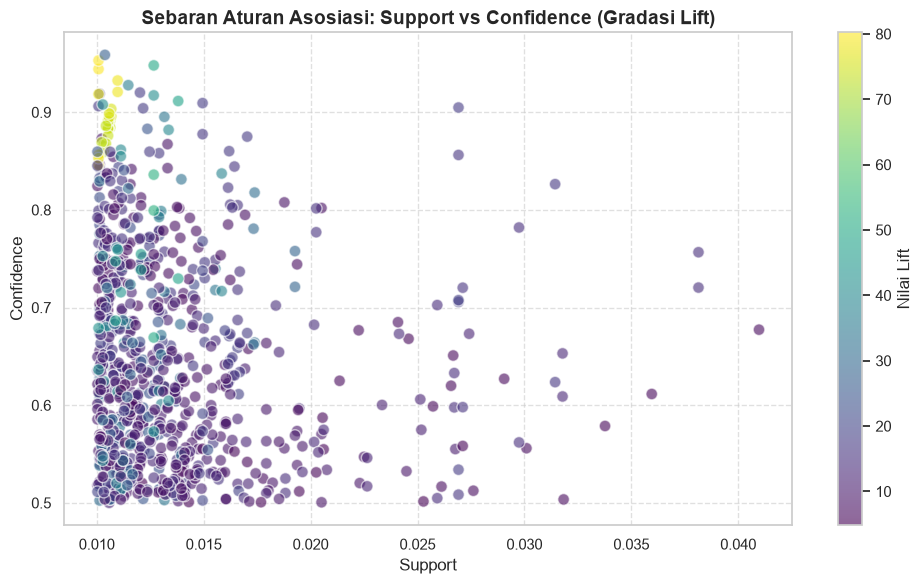

In [11]:
# Visualisasi Scatter Plot: Support vs Confidence bergradasi Lift
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    rules_initial['support'], 
    rules_initial['confidence'], 
    c=rules_initial['lift'], 
    cmap='viridis', 
    alpha=0.6, 
    edgecolors='w', 
    s=70
)
cbar = plt.colorbar(scatter)
cbar.set_label('Nilai Lift', fontsize=12)

plt.title('Sebaran Aturan Asosiasi: Support vs Confidence (Gradasi Lift)', fontsize=14, fontweight='bold')
plt.xlabel('Support', fontsize=12)
plt.ylabel('Confidence', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Pemilihan dan Interpretasi 3 Aturan Terbaik Berdasarkan Nilai Lift

---

#### 📌 Aturan 1: Bundling Produk Penanda Tanaman Herbal (*Herb Markers*)
> **Aturan:** `{HERB MARKER THYME} => {HERB MARKER PARSLEY, HERB MARKER ROSEMARY}`
> - **Support:** `0.0101` (1.01% dari seluruh transaksi toko memuat kombinasi ketiga item ini)
> - **Confidence:** `0.8565` (85.65% pelanggan yang membeli *Herb Marker Thyme* juga membeli *Parsley* dan *Rosemary*)
> - **Lift:** `80.22` (Kecenderungan membeli secara bersamaan **80.22 kali lebih tinggi** dibanding probabilitas pembelian secara acak/independen)

* **Interpretasi Bisnis Ritel:**
  Ketiga produk ini merupakan penanda label pot tanaman rempah dapur (*thyme, parsley, rosemary*). Konsumen yang menanam herbal di rumah hampir selalu menanam beberapa jenis rempah sekaligus dalam satu proyek berkebun.
* **Strategi Aksi Bisnis:**
  1. **Product Bundling:** Buat paket *"Herb Garden Starter Pack"* berisi 3 atau 4 penanda herbal sekaligus dengan potongan harga khusus (misal beli 3 hemat 15%).
  2. **Cross-Merchandising:** Posisikan ketiga produk ini saling bersebelahan pada rak fisik atau dalam satu grup halaman produk di situs web.

---

#### 📌 Aturan 2: Dekorasi Tematik Musiman (*Scandinavian Christmas Wood Decor*)
> **Aturan:** `{WOODEN HEART CHRISTMAS SCANDINAVIAN} => {WOODEN STAR CHRISTMAS SCANDINAVIAN}`
> - **Support:** `0.0155` (1.55% dari seluruh transaksi toko)
> - **Confidence:** `0.6125` (61.25% pembeli hiasan hati kayu juga membeli hiasan bintang kayu)
> - **Lift:** `24.36` (Peluang dibeli bersamaan **24.36 kali lipat** lebih tinggi dari ekspektasi normal)

* **Interpretasi Bisnis Ritel:**
  Kedua barang ini adalah hiasan gantung pohon Natal bermotif kayu rustic gaya Skandinavia. Konsumen yang mendekorasi rumah saat musim liburan cenderung menginginkan keselarasan tema (*visual harmony*).
* **Strategi Aksi Bisnis:**
  1. **Promosi Musiman:** Terapkan program *"Buy One Wooden Ornament, Get Second Ornament 50% Off"* selama periode menjelang Natal (November–Desember).
  2. **Checkout Recommendation:** Tampilkan *pop-up* otomatis di keranjang belanja saat pelanggan menambahkan hiasan bentuk hati: *"Pelanggan lain juga melengkapi dengan Wooden Star Ornament"*.

---

#### 📌 Aturan 3: Koleksi Cangkir Teh Elegan (*Regency Teacup and Saucer Collection*)
> **Aturan:** `{PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY TEACUP AND SAUCER} => {ROSES REGENCY TEACUP AND SAUCER}`
> - **Support:** `0.0210` (2.10% dari seluruh transaksi toko)
> - **Confidence:** `0.8653` (86.53% pelanggan yang membeli cangkir Pink dan Green melengkapinya dengan Roses)
> - **Lift:** `20.73` (Kecenderungan membeli trio cangkir ini **20.73 kali lebih tinggi** dari ekspektasi acak)

* **Interpretasi Bisnis Ritel:**
  Produk ini adalah perlengkapan jamuan minum teh bergaya vintage Regency. Pembeli cangkir teh tipe ini mayoritas memiliki persona kolektor atau penyelenggara pesta minum teh (*high tea / tea party*) yang membutuhkan set cangkir serasi aneka warna pastel.
* **Strategi Aksi Bisnis:**
  1. **"Complete the Set" Incentive:** Berikan voucher diskon khusus atau penawaran piring saji pendamping (*matching teapot / tea plates*) jika konsumen membeli set lengkap 3 warna.
  2. **Premium Gift Box Packaging:** Sediakan opsi kemasan kotak kado elegan berisi ketiga varian warna untuk momen hadiah (Mother's Day, pernikahan, dsb.).